# Transcription factors and cancer-cell proliferation (NCI-60)

**Question:** which transcription factors (TFs) are most associated with the proliferation of cancer cells?

**Approach**
1. Take gene expression from 57 cancer cell lines (NCI-60 panel).
2. Build a *proliferation score* from 28 cell-cycle marker genes.
3. Predict that score using **only TF expression** (a PyTorch neural network and a Random Forest, plus two baselines).
4. Rank the TFs by importance and check them against known cell-cycle regulators.

**Key findings** (details below)
- TF expression alone predicts the proliferation score well (R² between 0.70 and 0.85).
- With only 57 samples, a simple regularized linear model (Ridge) does as well as or better than the neural network and the Random Forest.
- The top-ranked TFs (**MYBL2, FOXM1, E2F1, E2F8**) are textbook cell-cycle regulators, so the model is learning real biology.

## 0. Setup

In [1]:
import os
import json
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import RepeatedKFold, cross_val_predict, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
BLUE = "#2b6cb0"

## 1. Data

Two public files from GitHub, downloaded automatically:
- `geneData.csv`: log2 expression of ~18,000 genes in 57 cancer cell lines (NCI-60 / CellMiner).
- `human_tfs.txt`: curated list of ~1,800 human transcription-factor genes (pySCENIC).

In [2]:
FILES = {
    "geneData.csv":
        "https://raw.githubusercontent.com/Mathelab/NCI60_GeneMetabolite_Data/master/geneData.csv",
    "human_tfs.txt":
        "https://raw.githubusercontent.com/aertslab/pySCENIC/master/resources/hs_hgnc_tfs.txt",
}

os.makedirs("data", exist_ok=True)
for name, url in FILES.items():
    dest = os.path.join("data", name)
    if not os.path.exists(dest):
        urllib.request.urlretrieve(url, dest)
    print(f"{name}: {os.path.getsize(dest):,} bytes")

geneData.csv: 17,548,294 bytes
human_tfs.txt: 11,353 bytes


## 2. Load and clean

- Transpose so that **rows = cell lines, columns = genes**.
- Drop genes with missing values or no variation (they carry no information).

In [3]:
expr = pd.read_csv("data/geneData.csv", index_col=0).T   # cell lines x genes

expr = expr.dropna(axis=1)
expr = expr.loc[:, expr.std(axis=0) > 0]

print("Cell lines:", expr.shape[0])
print("Genes after cleaning:", expr.shape[1])
expr.iloc[:5, :5]

Cell lines: 57
Genes after cleaning: 17987


,PRPF8,CAPNS1,RPL35,EIF3D,PARK7
786-0,8.940314,10.615170,11.726303,10.357937,11.025624
A498,9.243888,10.747773,11.446696,9.535956,10.452499
A549/ATCC,9.841486,11.429930,11.489120,9.719988,10.982388
ACHN,9.219532,10.462400,11.418538,10.570425,10.491953
BT-549,9.545351,10.733609,11.861630,10.052636,11.259920


## 3. Target (proliferation) and features (TFs)

There is no ready-made "cell growth" column, so we build one. 28 proliferation / cell-cycle
marker genes (MKI67, PCNA, TOP2A, CCNB1...) are z-scored and averaged into one number per
cell line: *how proliferative is it?*

The features are the expression of the TFs. TFs and marker genes **must not overlap**,
otherwise the model could "cheat" by predicting a gene from itself.

In [4]:
PROLIF_MARKERS = ["MKI67","PCNA","TOP2A","CCNB1","CCNB2","CDK1","CDC20","AURKA",
                  "AURKB","BUB1","BUB1B","CCNA2","CENPF","TYMS","RRM2","UBE2C",
                  "BIRC5","KIF11","MCM2","MCM3","MCM4","MCM5","MCM6","MCM7",
                  "PLK1","TK1","ZWINT","NUSAP1"]

with open("data/human_tfs.txt") as f:
    tfs_all = [l.strip() for l in f if l.strip()]

markers = [g for g in PROLIF_MARKERS if g in expr.columns]
tf_cols = [g for g in tfs_all if g in expr.columns and g not in markers]

print("Proliferation markers found:", len(markers))
print("TFs available as features:", len(tf_cols))
print("TF / marker overlap (must be 0):", len(set(tf_cols) & set(markers)))

Proliferation markers found: 28
TFs available as features: 1589
TF / marker overlap (must be 0): 0


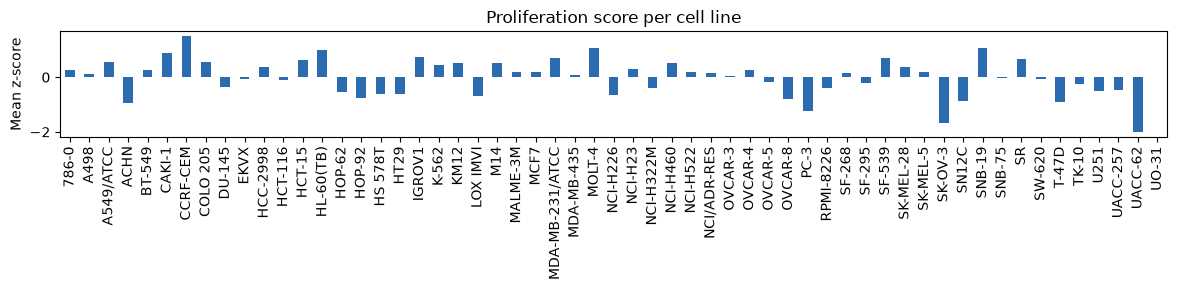

In [5]:
m = expr[markers]
y = ((m - m.mean()) / m.std()).mean(axis=1)   # proliferation score (mean z-score)
X = expr[tf_cols]                              # features = TF expression

y.plot(kind="bar", figsize=(12, 3), color=BLUE, title="Proliferation score per cell line")
plt.ylabel("Mean z-score")
plt.tight_layout()
plt.show()

## 4. Model: neural network in PyTorch

A deliberately small network (1 hidden layer of 16 neurons + dropout): with only 57
samples, a large network would memorize instead of learning.

It is wrapped in a class with `.fit()` / `.predict()` so it behaves like any scikit-learn
model and can reuse the same cross-validation tools as the Random Forest.

In [6]:
class TorchMLPRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, hidden=16, dropout=0.3, lr=1e-2, wd=1e-3, epochs=300):
        self.hidden, self.dropout = hidden, dropout
        self.lr, self.wd, self.epochs = lr, wd, epochs

    def fit(self, X, y):
        torch.manual_seed(SEED)
        X = torch.tensor(np.asarray(X), dtype=torch.float32)
        y = np.asarray(y, dtype=np.float32)
        self.y_mean_, self.y_std_ = y.mean(), y.std() + 1e-8
        yt = torch.tensor((y - self.y_mean_) / self.y_std_).view(-1, 1)

        self.net_ = nn.Sequential(
            nn.Linear(X.shape[1], self.hidden),
            nn.ReLU(),
            nn.Dropout(self.dropout),
            nn.Linear(self.hidden, 1),
        )
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.wd)
        loss_fn = nn.MSELoss()
        self.net_.train()
        for _ in range(self.epochs):
            opt.zero_grad()
            loss_fn(self.net_(X), yt).backward()
            opt.step()
        return self

    def predict(self, X):
        self.net_.eval()
        X = torch.tensor(np.asarray(X), dtype=torch.float32)
        with torch.no_grad():
            pred = self.net_(X).numpy().ravel()
        return pred * self.y_std_ + self.y_mean_

## 5. Pipeline: scaling + feature selection

`SelectKBest` keeps the 50 TFs most correlated with the target.

**Important:** it lives inside a scikit-learn `Pipeline`, together with the scaler and the
model. That way, in every cross-validation fold the selection is recomputed using only that
fold's training data. Selecting features once on the full dataset would let the model "see"
the test samples and inflate the metrics (data leakage).

In [7]:
K_FEATURES = 50

def make_pipeline(model):
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_regression, k=K_FEATURES)),
        ("model", model),
    ])

## 6. Evaluation (RMSE, MAE, R²)

With only 57 samples a single train/test split is unstable. We use **Repeated K-Fold**
(5 folds, repeated 5 times with different seeds) and report mean ± standard deviation.

Two baselines give context: always predicting the mean, and Ridge (regularized linear regression).

In [8]:
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ridge":         Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=500, random_state=SEED),
    "PyTorch MLP":   TorchMLPRegressor(),
}

def evaluate(model, X, y, cv):
    pipe = make_pipeline(model)
    rmse = -cross_val_score(pipe, X, y, cv=cv, scoring="neg_root_mean_squared_error")
    mae  = -cross_val_score(pipe, X, y, cv=cv, scoring="neg_mean_absolute_error")
    r2   =  cross_val_score(pipe, X, y, cv=cv, scoring="r2")
    return {"RMSE": (rmse.mean(), rmse.std()),
            "MAE":  (mae.mean(),  mae.std()),
            "R2":   (r2.mean(),   r2.std())}

results = {name: evaluate(m, X, y, cv) for name, m in models.items()}

summary = pd.DataFrame({
    name: {k: f"{v[0]:.3f} ± {v[1]:.3f}" for k, v in r.items()}
    for name, r in results.items()
}).T
summary

,RMSE,MAE,R2
Mean baseline,0.669 ± 0.168,0.543 ± 0.128,-0.124 ± 0.175
Ridge,0.229 ± 0.058,0.182 ± 0.048,0.844 ± 0.098
Random Forest,0.342 ± 0.110,0.254 ± 0.087,0.702 ± 0.107
PyTorch MLP,0.267 ± 0.078,0.212 ± 0.063,0.789 ± 0.124


## 7. Predicted vs. actual (out-of-fold)

Each cell line is predicted by a model that **never saw it** during training
(5-fold, one repetition, for a clean plot).

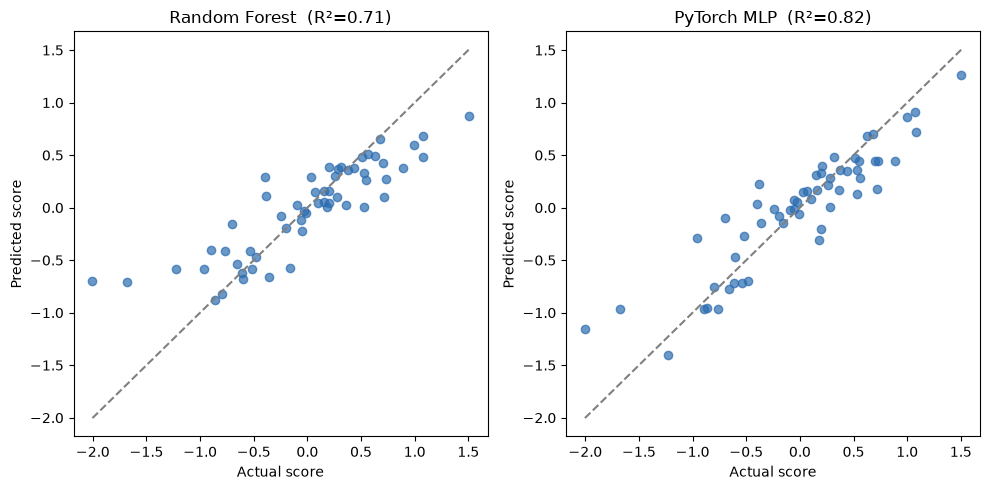

In [9]:
oof_cv = RepeatedKFold(n_splits=5, n_repeats=1, random_state=SEED)
oof_rf = cross_val_predict(make_pipeline(models["Random Forest"]), X, y, cv=oof_cv)
oof_nn = cross_val_predict(make_pipeline(models["PyTorch MLP"]),   X, y, cv=oof_cv)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, name, oof in zip(axes, ["Random Forest", "PyTorch MLP"], [oof_rf, oof_nn]):
    ax.scatter(y, oof, alpha=0.7, color=BLUE)
    lims = [min(y.min(), oof.min()), max(y.max(), oof.max())]
    ax.plot(lims, lims, "--", color="grey")
    ax.set_xlabel("Actual score"); ax.set_ylabel("Predicted score")
    ax.set_title(f"{name}  (R²={r2_score(y, oof):.2f})")
plt.tight_layout()
plt.show()

## 8. Which TFs matter most?

We select the 50 TFs using all the data (the model was already validated above without
leakage; this step is only for the final ranking, which is descriptive, not a performance metric).

Two kinds of importance:
- **Random Forest built-in**: fast, but biased toward variables with many distinct values.
- **Permutation importance**: shuffle one TF's values and measure how much the model gets worse. More reliable, so it is the one used for ranking.

In [10]:
Xs = StandardScaler().fit_transform(X)
sel = SelectKBest(f_regression, k=K_FEATURES).fit(Xs, y)
sel_tfs = np.array(tf_cols)[sel.get_support()]
Xsel = sel.transform(Xs)

rf = RandomForestRegressor(n_estimators=500, random_state=SEED).fit(Xsel, y)
perm = permutation_importance(rf, Xsel, y, n_repeats=50, random_state=SEED)

imp = (pd.DataFrame({"TF": sel_tfs,
                     "rf_importance": rf.feature_importances_,
                     "perm_importance": perm.importances_mean})
         .sort_values("perm_importance", ascending=False)
         .reset_index(drop=True))

imp.head(15)

,TF,rf_importance,perm_importance
0,MYBL2,0.210554,0.119913
1,H2AFZ,0.114359,0.053989
2,KIF22,0.119252,0.049398
3,FOXM1,0.103678,0.044518
4,E2F8,0.083842,0.035582
5,DTL,0.075376,0.034263
6,DNMT1,0.043826,0.017525
7,FOXP2,0.016945,0.010583
8,E2F1,0.020569,0.009530
9,DDIT3,0.011915,0.005895


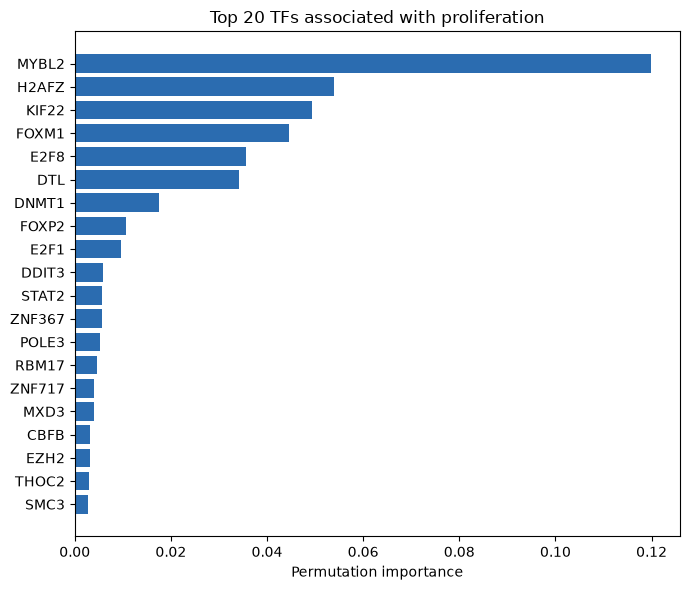

In [11]:
top = imp.head(20).iloc[::-1]
plt.figure(figsize=(7, 6))
plt.barh(top["TF"], top["perm_importance"], color=BLUE)
plt.xlabel("Permutation importance")
plt.title("Top 20 TFs associated with proliferation")
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/top_tfs.png", dpi=150)   # reused in the README
plt.show()

## 9. Biological validation

Do the top TFs match known cell-cycle regulators? If so, the model is learning real
biology and not noise.

In [12]:
known_drivers = {"MYBL2", "FOXM1", "E2F1", "E2F2", "E2F3", "E2F8", "MYC", "TFDP1"}
top15 = list(imp.head(15)["TF"])
hits = [t for t in top15 if t in known_drivers]

print("Top 15 TFs:", top15)
print("\nKnown proliferation regulators in the top 15:", hits)

Top 15 TFs: ['MYBL2', 'H2AFZ', 'KIF22', 'FOXM1', 'E2F8', 'DTL', 'DNMT1', 'FOXP2', 'E2F1', 'DDIT3', 'STAT2', 'ZNF367', 'POLE3', 'RBM17', 'ZNF717']

Known proliferation regulators in the top 15: ['MYBL2', 'FOXM1', 'E2F8', 'E2F1']


## 10. Save results

In [13]:
os.makedirs("results", exist_ok=True)
imp.to_csv("results/tf_importance.csv", index=False)

metrics_json = {name: {k: [round(v[0], 4), round(v[1], 4)] for k, v in r.items()}
                for name, r in results.items()}
with open("results/metrics.json", "w") as f:
    json.dump(metrics_json, f, indent=2)

print("Saved: results/tf_importance.csv, results/metrics.json, results/top_tfs.png")

Saved: results/tf_importance.csv, results/metrics.json, results/top_tfs.png


## Conclusions

- TF expression alone predicts the proliferation score well (R² ≈ 0.7–0.85 across models).
- With only 57 samples, Ridge (linear, regularized) matches or beats the neural network and the Random Forest. This is expected, and we report it as is.
- The most important TFs (**MYBL2, FOXM1, E2F1, E2F8...**) are known cell-cycle regulators, which supports the idea that the model captures real biology.

**Limitations**
- n = 57 is small (inherent to the NCI-60 panel).
- The target is a transcriptomic proxy for proliferation, not a growth rate measured in the lab.
- Features and target come from the same expression platform, so shared technical effects are possible.
- The importance ranking is computed on the training data (descriptive only), and the TF list includes some chromatin factors (e.g. H2AFZ) that are not classical TFs.